# C1_04_Input_Ablation
- X = X_flat_c1_v2.npy
- Y = y_labels_c1_v2.csv
- Built by Garmin_C1_DataBuild

### Does the previous window help? Random Forest and Simple DNN on four input sets

| Input set | What the model sees |
|---|---|
| `none` | the current window only (the control) |
| `prev1` | current + the window just before it |
| `prev1+2` | current + the two windows before it |
| `prev2 only` | current + the window TWO back, skipping the one just before |


## 1. Setup and configuration

In [1]:
from pathlib import Path
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, recall_score

import tensorflow as tf
from tensorflow import keras

DATA_DIR = Path(r"C:\dev\UoW\DATAX504\Final Assignment\garmin_data\Processed")
X_FLAT_PATH = DATA_DIR / "X_flat_c1_v2.npy"
Y_LABELS_PATH = DATA_DIR / "y_labels_c1_v2.csv"
OUTPUT_CSV = DATA_DIR / "c1_context_test_results_2026-10-04.csv"

WINDOW_SECONDS = 30
SEQ_COLS = 120          # first 120 columns of X_flat = HR, speed, cadence, temperature (30 each); column 120 = distance

# Which earlier windows to add: lag 1 = the window just before, lag 2 = two back, ...
CONTEXT_SETS = {
    "none":       [],
    "prev1":      [1],
    "prev1+2":    [1, 2],
    "prev2 only": [2],
}

# Random Forest (one fit per input set)
N_TREES = 100
N_JOBS = 2

# Simple DNN (16 -> 8 -> softmax) on several seeds
DNN_SEEDS = [42, 7, 123]
DNN_EPOCHS = 40
DNN_PATIENCE = 5
DNN_BATCH = 256

REFERENCE = {"Random Forest (earlier baseline)": 0.567, "Simple DNN (earlier baseline)": 0.574}


## 2. Load data and build the common window set

Each window's earlier windows are found by matching `(file_path, start_s - 30 × lag)`. The first windows of each run have no earlier window, so they are left out. Every input set is scored on the same windows, those that have all the earlier windows. The code checks that each earlier window comes from the same file and exactly the expected time before.


In [2]:
X_flat = np.load(X_FLAT_PATH).astype("float32")
y_df = pd.read_csv(Y_LABELS_PATH, parse_dates=["date"])
assert len(X_flat) == len(y_df), "X and Y row counts differ"
y_df["start_s"] = y_df["start_s"].astype(int)
print(f"X_flat {X_flat.shape}, {len(y_df)} labelled windows")

row_lookup = pd.Series(np.arange(len(y_df)), index=pd.MultiIndex.from_arrays([y_df["file_path"], y_df["start_s"]]))
assert row_lookup.index.is_unique, "duplicate (file_path, start_s) keys"

all_lags = sorted({lag for lags in CONTEXT_SETS.values() for lag in lags})
lag_rows = {}
for lag in all_lags:
    keys = pd.MultiIndex.from_arrays([y_df["file_path"], y_df["start_s"] - WINDOW_SECONDS * lag])
    lag_rows[lag] = row_lookup.reindex(keys).to_numpy()           # NaN where that earlier window does not exist

common = np.ones(len(y_df), dtype=bool)
for lag in all_lags:
    common &= ~np.isnan(lag_rows[lag])
print(f"Windows with every earlier window available: {int(common.sum())} of {len(y_df)} ({100 * common.mean():.1f}%)")

# Alignment assertions: each earlier window must be the same file, exactly lag*30 s earlier
for lag in all_lags:
    r = lag_rows[lag][common].astype(int)
    assert (y_df["file_path"].to_numpy()[r] == y_df["file_path"].to_numpy()[common]).all(), "lag row from a different file"
    assert (y_df["start_s"].to_numpy()[r] == y_df["start_s"].to_numpy()[common] - WINDOW_SECONDS * lag).all(), "lag row not the expected time"
print("OK: every earlier window is from the same file and exactly the expected time before.")

classes = np.array(sorted(y_df["c1_target"].unique()))
class_to_int = {c: i for i, c in enumerate(classes)}
y_all = np.array([class_to_int[c] for c in y_df["c1_target"]])
print("Classes:", class_to_int)


X_flat (197341, 121), 197341 labelled windows
Windows with every earlier window available: 193591 of 197341 (98.1%)
OK: every earlier window is from the same file and exactly the expected time before.
Classes: {np.str_('Base'): 0, np.str_('Declining'): 1, np.str_('Improving'): 2, np.str_('Recovery'): 3}


## 3. Split by run and build features

The split is the same as in the baselines. The test runs are set aside and never built. Features are the current window's 121 values, plus the raw readings of any earlier windows in the input set.

In [3]:
run_idx_all = y_df["run_idx"].to_numpy()
unique_runs = np.unique(run_idx_all)
train_runs, held_out_runs = train_test_split(unique_runs, test_size=0.2, random_state=42)
trainval_idx = np.where(np.isin(run_idx_all, train_runs))[0]
trainval_run_idx = run_idx_all[trainval_idx]
fit_runs, val_runs = train_test_split(np.unique(trainval_run_idx), test_size=0.15, random_state=42)

fit_idx = trainval_idx[np.isin(trainval_run_idx, fit_runs) & common[trainval_idx]]
val_idx = trainval_idx[np.isin(trainval_run_idx, val_runs) & common[trainval_idx]]
y_fit, y_val = y_all[fit_idx], y_all[val_idx]
print(f"Fit: {len(fit_idx)} windows from {len(fit_runs)} runs | Val: {len(val_idx)} windows from {len(val_runs)} runs")
print("(test runs excluded and never built)")

majority = np.bincount(y_fit, minlength=len(classes)).argmax()          # biggest class, learned on FIT only
naive_acc = float((y_val == majority).mean())
print(f"Naive (always predict '{classes[majority]}') validation accuracy: {naive_acc:.3f}")


def build_features(lags, idx):
    """Current window (all 121 columns) + the raw sequence columns (first 120) of each earlier window."""
    parts = [X_flat[idx]]
    for lag in lags:
        parts.append(X_flat[lag_rows[lag][idx].astype(int), :SEQ_COLS])
    return np.concatenate(parts, axis=1)


for name, lags in CONTEXT_SETS.items():
    print(f"  {name:<12} -> {121 + SEQ_COLS * len(lags)} features")


Fit: 130416 windows from 1275 runs | Val: 24095 windows from 225 runs
(test runs excluded and never built)
Naive (always predict 'Base') validation accuracy: 0.395
  none         -> 121 features
  prev1        -> 241 features
  prev1+2      -> 361 features
  prev2 only   -> 241 features


## 4. Random Forest on each input set

In [4]:
rf_rows = []
for name, lags in CONTEXT_SETS.items():
    Xf, Xv = build_features(lags, fit_idx), build_features(lags, val_idx)
    t0 = time.time()
    rf = RandomForestClassifier(n_estimators=N_TREES, class_weight="balanced", random_state=42, n_jobs=N_JOBS)
    rf.fit(Xf, y_fit)
    pred = rf.predict(Xv)
    minutes = (time.time() - t0) / 60
    acc = accuracy_score(y_val, pred)
    row = {"input_set": name, "n_features": Xf.shape[1], "rf_acc": float(acc), "rf_skill": float(acc - naive_acc),
           "rf_macro_f1": float(f1_score(y_val, pred, average="macro")), "rf_minutes": float(minutes)}
    for cls, r in zip(classes, recall_score(y_val, pred, average=None, labels=np.arange(len(classes)), zero_division=0)):
        row[f"rf_recall_{cls}"] = float(r)
    rf_rows.append(row)
    print(f"RF  {name:<12} acc {acc:.3f} | skill {acc - naive_acc:+.3f} | {minutes:.1f} min", flush=True)
rf_df = pd.DataFrame(rf_rows)


RF  none         acc 0.565 | skill +0.170 | 1.5 min
RF  prev1        acc 0.587 | skill +0.191 | 2.1 min
RF  prev1+2      acc 0.586 | skill +0.191 | 2.8 min
RF  prev2 only   acc 0.580 | skill +0.185 | 2.2 min


## 5. Simple DNN on each input set (3 seeds)

The same Simple DNN as the baselines (16 → 8 → softmax, dropout 0.2), trained on each input set with seeds 42, 7 and 123. Inputs are scaled using the fit windows only.

In [5]:
def run_dnn(Xf, yf, Xv, yv, seed):
    keras.utils.set_random_seed(seed)
    scaler = StandardScaler().fit(Xf)                                    # fit on FIT windows only
    Xf_s, Xv_s = scaler.transform(Xf).astype("float32"), scaler.transform(Xv).astype("float32")
    model = keras.Sequential([
        keras.layers.Input(shape=(Xf_s.shape[1],)),
        keras.layers.Dense(16, activation="relu"),
        keras.layers.Dropout(0.2),
        keras.layers.Dense(8, activation="relu"),
        keras.layers.Dense(len(classes), activation="softmax"),
    ])
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    model.fit(Xf_s, yf, validation_data=(Xv_s, yv), epochs=DNN_EPOCHS, batch_size=DNN_BATCH, verbose=0,
              callbacks=[keras.callbacks.EarlyStopping(patience=DNN_PATIENCE, restore_best_weights=True)])
    pred = model.predict(Xv_s, batch_size=2048, verbose=0).argmax(axis=1)
    keras.backend.clear_session()
    return pred


dnn_rows = []
for name, lags in CONTEXT_SETS.items():
    Xf, Xv = build_features(lags, fit_idx), build_features(lags, val_idx)
    accs, f1s, recs = [], [], []
    t0 = time.time()
    for seed in DNN_SEEDS:
        pred = run_dnn(Xf, y_fit, Xv, y_val, seed)
        accs.append(accuracy_score(y_val, pred))
        f1s.append(f1_score(y_val, pred, average="macro"))
        recs.append(recall_score(y_val, pred, average=None, labels=np.arange(len(classes)), zero_division=0))
    minutes = (time.time() - t0) / 60
    row = {"input_set": name, "dnn_acc_mean": float(np.mean(accs)),
           "dnn_acc_std": float(np.std(accs, ddof=1)) if len(accs) > 1 else np.nan,
           "dnn_skill": float(np.mean(accs) - naive_acc), "dnn_macro_f1": float(np.mean(f1s)), "dnn_minutes": float(minutes)}
    for k, cls in enumerate(classes):
        row[f"dnn_recall_{cls}"] = float(np.mean([r[k] for r in recs]))
    dnn_rows.append(row)
    print(f"DNN {name:<12} acc {np.mean(accs):.3f} +/- {row['dnn_acc_std']:.3f} (seeds {[round(a, 3) for a in accs]}) | {minutes:.1f} min", flush=True)
dnn_df = pd.DataFrame(dnn_rows)



DNN none         acc 0.579 +/- 0.001 (seeds [0.581, 0.578, 0.579]) | 1.6 min
DNN prev1        acc 0.593 +/- 0.001 (seeds [0.594, 0.592, 0.592]) | 1.4 min
DNN prev1+2      acc 0.592 +/- 0.005 (seeds [0.596, 0.593, 0.586]) | 1.4 min
DNN prev2 only   acc 0.590 +/- 0.002 (seeds [0.592, 0.589, 0.589]) | 1.3 min


## 6. Results

Saved to C:\dev\UoW\DATAX504\Final Assignment\garmin_data\Processed\c1_context_test_results_2026-10-04.csv

Naive baseline on these windows: 0.395
Earlier baselines (different windows/settings, for rough orientation only): Random Forest (earlier baseline) 0.567, Simple DNN (earlier baseline) 0.574

 input_set  n_features  rf_acc  rf_skill  dnn_acc_mean  dnn_acc_std  dnn_skill  rf_recall_Declining  rf_recall_Improving  dnn_recall_Declining  dnn_recall_Improving
      none         121   0.565     0.170         0.579        0.001      0.184                0.580                0.570                 0.522                 0.515
     prev1         241   0.587     0.191         0.593        0.001      0.198                0.590                0.597                 0.546                 0.524
   prev1+2         361   0.586     0.191         0.592        0.005      0.197                0.587                0.594                 0.535                 0.514
prev2 only         241   0.580     0.185

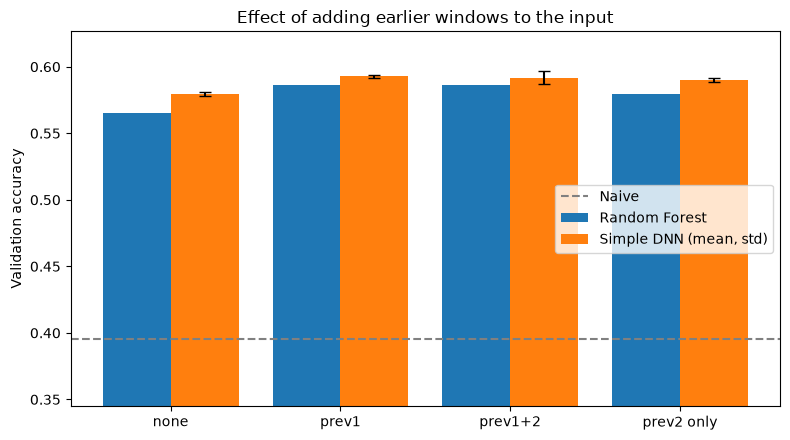


How to read: if prev1 helps but 'prev2 only' does not, the gain is mostly the overlap with the label's
own baseline. If 'prev2 only' helps too, the extra history is genuinely informative.


In [6]:
results = rf_df.merge(dnn_df, on="input_set")
results.to_csv(OUTPUT_CSV, index=False)
print(f"Saved to {OUTPUT_CSV}\n")

print(f"Naive baseline on these windows: {naive_acc:.3f}")
print("Earlier baselines (different windows/settings, for rough orientation only): "
      + ", ".join(f"{k} {v:.3f}" for k, v in REFERENCE.items()) + "\n")

cols = ["input_set", "n_features", "rf_acc", "rf_skill", "dnn_acc_mean", "dnn_acc_std", "dnn_skill",
        "rf_recall_Declining", "rf_recall_Improving", "dnn_recall_Declining", "dnn_recall_Improving"]
print(results[cols].to_string(index=False, float_format=lambda v: f"{v:.3f}"))

base = results[results["input_set"] == "none"].iloc[0]
print("\nChange versus the 'none' control (same windows):")
for _, r in results.iterrows():
    if r["input_set"] == "none":
        continue
    d_rf = r["rf_acc"] - base["rf_acc"]
    d_dnn = r["dnn_acc_mean"] - base["dnn_acc_mean"]
    noise = 2 * max(r["dnn_acc_std"], base["dnn_acc_std"]) if not np.isnan(r["dnn_acc_std"]) else np.nan
    flag = "" if np.isnan(noise) else ("  (beyond DNN seed noise)" if abs(d_dnn) > noise else "  (within DNN seed noise)")
    print(f"  {r['input_set']:<12} RF {d_rf:+.3f} | DNN {d_dnn:+.3f}{flag}")

fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(results))
ax.bar(x - 0.2, results["rf_acc"], width=0.4, label="Random Forest")
ax.bar(x + 0.2, results["dnn_acc_mean"], width=0.4, yerr=results["dnn_acc_std"], capsize=4, label="Simple DNN (mean, std)")
ax.axhline(naive_acc, color="grey", linestyle="--", label="Naive")
ax.set_xticks(x)
ax.set_xticklabels(results["input_set"])
ax.set_ylim(max(0.0, naive_acc - 0.05), None)
ax.set_ylabel("Validation accuracy")
ax.set_title("Effect of adding earlier windows to the input")
ax.legend()
plt.tight_layout()
plt.show()

print("\nHow to read: if prev1 helps but 'prev2 only' does not, the gain is mostly the overlap with the label's")
print("own baseline. If 'prev2 only' helps too, the extra history is genuinely informative.")
